# Evaluation sur photos reelles Jumia (ecart de domaine)

Ce notebook mesure l'ecart entre les performances du modele sur le val split Kaggle
("photos propres") et sur un petit set de vraies photos produits (`data/real_world_test/`),
constitue a la main par l'equipe (3-4 images par categorie officielle).

A executer **apres** avoir entraine et sauvegarde le modele (`02_training_cnn.ipynb`).

In [1]:
import json
from pathlib import Path

import numpy as np
import tensorflow as tf

IMG_SIZE = (224, 224)
MODEL_PATH = Path("../models/modele_eco_sort.keras")
CLASS_NAMES_PATH = Path("../models/class_names.json")
DATA_DIR = Path("../data/real_world_test")


## 1. Chargement du modele et du set de test reel

In [2]:
with open(CLASS_NAMES_PATH) as f:
    class_names = json.load(f)

model = tf.keras.models.load_model(MODEL_PATH)

ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=IMG_SIZE,
    batch_size=16,
    label_mode="categorical",
    shuffle=False,
)

real_class_names = ds.class_names
print("Classes attendues (entrainement) :", class_names)
print("Classes trouvees (real_world_test) :", real_class_names)
assert real_class_names == class_names, "Verifie les noms de dossiers dans data/real_world_test/"


Found 17 files belonging to 5 classes.
Classes attendues (entrainement) : ['bleue', 'd3e', 'jaune', 'marron', 'verte']
Classes trouvees (real_world_test) : ['bleue', 'd3e', 'jaune', 'marron', 'verte']


## 2. Predictions et accuracy sur les vraies photos

In [3]:
y_true, y_pred = [], []
for images, labels in ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)
accuracy = (y_true == y_pred).mean()

print(f"Accuracy sur photos reelles Jumia : {accuracy:.2%} ({len(y_true)} images)")


Accuracy sur photos reelles Jumia : 47.06% (17 images)


## 3. Matrice de confusion

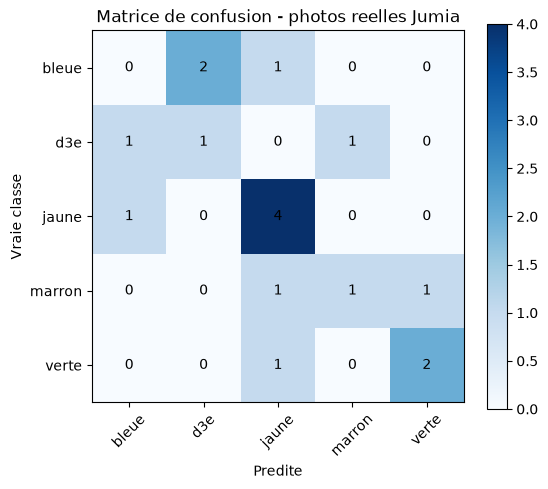

In [4]:
import matplotlib.pyplot as plt

n = len(class_names)
confusion = np.zeros((n, n), dtype=int)
for t, p in zip(y_true, y_pred):
    confusion[t, p] += 1

plt.figure(figsize=(6, 5))
plt.imshow(confusion, cmap="Blues")
plt.xticks(range(n), class_names, rotation=45)
plt.yticks(range(n), class_names)
plt.xlabel("Predite")
plt.ylabel("Vraie classe")
for i in range(n):
    for j in range(n):
        plt.text(j, i, confusion[i, j], ha="center", va="center")
plt.title("Matrice de confusion - photos reelles Jumia")
plt.colorbar()
plt.show()


## 4. Conclusion

Compare cette accuracy a celle obtenue sur le val Kaggle dans `02_training_cnn.ipynb`.

- Ecart faible (< 5-10 points) : le modele generalise correctement, RAS.
- Ecart important : renforcer l'augmentation de donnees, ou envisager d'ajouter
  quelques vraies photos e-commerce a l'entrainement (pas seulement au test).

Une fois ce diagnostic fait, previens-moi : je convertirai ce notebook en script
`src/ml/evaluate_real_world.py` reproductible pour le livrable final.